# Argentina y el resto: quién explica el crecimiento y la caída del turismo receptivo en Chile
**Proyecto Python · Portafolio de Análisis de Datos Junior (turismo de Chile) · DATOS REALES**

> **Datos reales y oficiales.** Fuente: Sernatur (SIET), archivo oficial "Cuadros de llegadas de turistas extranjeros" (publicación de agosto 2026): llegadas por nacionalidad y mes, 2008 a julio de 2026. Las cifras incluyen chilenos residentes en el exterior (nacionalidad "CHILE") y son preliminares desde julio de 2020.

**Escenario simulado:** soy analista de datos de un **hotel** urbano de tamaño medio con muchos huéspedes extranjeros. El encargo es una simulación; los datos y las cifras son reales.

> **Querido/a analista,** estamos armando el presupuesto y las campañas del próximo año y necesitamos estimar algunas métricas del mercado de turistas extranjeros:
> 1. ¿Cuánto pesa Argentina en las llegadas y cómo ha cambiado desde 2008?
> 2. ¿Quién explicó el crecimiento de 2025 y quién explica la caída de 2026?
> 3. ¿Qué pasa con el resto de los mercados, sin Argentina?
> 4. ¿Es distinta la estacionalidad de Argentina y la del resto?
> 5. ¿Con qué rango deberíamos presupuestar 2026?
>
> Quedamos a la espera de tus resultados. ¡Gracias!

**Herramienta protagonista:** Python (pandas, NumPy y matplotlib).

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30); pd.set_option("display.float_format", lambda x: f"{x:,.1f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
D = "../datos_oficiales/"
AZUL, VERDE, ROJO, GRIS = "#1F3A4D", "#2E7D6B", "#C0392B", "#8A9BA8"
MES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

df = pd.read_csv(D + "siet/llegadas_nacionalidad_mes_largo.csv")
AGRUP = {"AFRICA", "AMERICA CENTRAL", "AMERICA DEL NORTE", "AMERICA DEL SUR", "ASIA", "CARIBE", "EUROPA", "MEDIO ORIENTE", "OCEANIA", "Total general"}
total = df[df.nacionalidad == "Total general"].set_index(["anio", "mes"]).llegadas
hojas = df[~df.nacionalidad.isin(AGRUP)].copy()          # países + categorías "O. ..." (no se doble cuentan)
print("Filas:", len(df), "| nacionalidades (hojas):", hojas.nacionalidad.nunique(), "| período:", df.anio.min(), "a", df.anio.max(), "(2026 hasta julio)")

Filas: 36126 | nacionalidades (hojas): 152 | período: 2008 a 2026 (2026 hasta julio)


## 1. Controles de calidad
Antes de analizar: ¿la suma de países calza con el total?, ¿los totales anuales coinciden con los comunicados oficiales?, ¿esta fuente coincide con la serie mensual que ya usé en el portafolio?

In [2]:
suma_hojas = hojas.groupby(["anio", "mes"]).llegadas.sum()
print("Suma de países vs 'Total general': diferencia máxima =", float((suma_hojas - total).abs().max()))

oficial = {2017: 6449883, 2022: 2030479, 2023: 3730507, 2024: 5239233, 2025: 6004567}
anual = total.groupby("anio").sum()
ctrl = pd.DataFrame({"archivo": {a: anual[a] for a in oficial}, "comunicado oficial": oficial}); ctrl["diferencia"] = ctrl["archivo"] - ctrl["comunicado oficial"]
print("\nTotales anuales:\n", ctrl.astype(int).to_string())

previa = pd.read_csv(D + "llegadas_mensuales_nacional.csv").set_index(["anio", "mes"]).llegadas
dif = (previa - total.reindex(previa.index)).abs()
print(f"\nSerie mensual transcrita antes (31 meses) vs archivo oficial: {int((dif > 0).sum())} meses con diferencia")
print("Ene-may 2026:", int(total.loc[2026].loc[1:5].sum()), "| oficial SIET: 2.287.859")

Suma de países vs 'Total general': diferencia máxima = 0.0

Totales anuales:
       archivo  comunicado oficial  diferencia
2017  6449883             6449883           0
2022  2030479             2030479           0
2023  3730507             3730507           0
2024  5239233             5239233           0
2025  6004567             6004567           0

Serie mensual transcrita antes (31 meses) vs archivo oficial: 0 meses con diferencia
Ene-may 2026: 2287859 | oficial SIET: 2.287.859


## 2. ¿Cuánto pesa Argentina y cómo ha cambiado?

           total   argentina       resto  pct_argentina
anio                                                   
2008 2,710,024.0   863,897.0 1,846,127.0           31.9
2009 2,759,695.0   996,813.0 1,762,882.0           36.1
2010 2,800,637.0 1,001,125.0 1,799,512.0           35.7
2011 3,137,285.0 1,118,767.0 2,018,518.0           35.7
2012 3,554,279.0 1,377,645.0 2,176,634.0           38.8
2013 3,576,204.0 1,362,752.0 2,213,452.0           38.1
2014 3,674,391.0 1,325,503.0 2,348,888.0           36.1
2015 4,478,336.0 1,946,876.0 2,531,460.0           43.5
2016 5,640,700.0 2,900,709.0 2,739,991.0           51.4
2017 6,449,883.0 3,323,771.0 3,126,112.0           51.5
2018 5,722,928.0 2,422,235.0 3,300,693.0           42.3
2019 4,517,962.0 1,435,467.0 3,082,495.0           31.8
2020 1,119,094.0   414,457.0   704,637.0           37.0
2021   190,022.0    20,912.0   169,110.0           11.0
2022 2,030,479.0   652,097.0 1,378,382.0           32.1
2023 3,730,507.0 1,205,662.0 2,524,845.0        

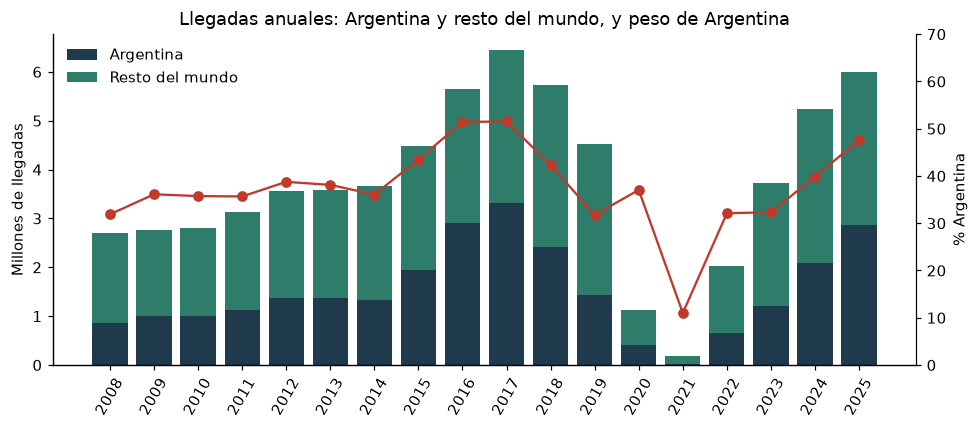

In [3]:
arg = hojas[hojas.nacionalidad == "ARGENTINA"].groupby(["anio", "mes"]).llegadas.sum()
a = pd.DataFrame({"total": total.groupby("anio").sum(), "argentina": arg.groupby("anio").sum()}).loc[2008:2025]
a["resto"] = a.total - a.argentina; a["pct_argentina"] = 100 * a.argentina / a.total
print(a.round(1).to_string())

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(a.index, a.argentina / 1e6, color=AZUL, label="Argentina"); ax.bar(a.index, a.resto / 1e6, bottom=a.argentina / 1e6, color=VERDE, label="Resto del mundo")
ax.set_ylabel("Millones de llegadas"); ax.set_xticks(a.index); ax.tick_params(axis="x", rotation=60); ax.legend(frameon=False, loc="upper left")
ax2 = ax.twinx(); ax2.plot(a.index, a.pct_argentina, color=ROJO, marker="o"); ax2.set_ylim(0, 70); ax2.set_ylabel("% Argentina"); ax2.spines["right"].set_visible(True)
ax.set_title("Llegadas anuales: Argentina y resto del mundo, y peso de Argentina"); plt.tight_layout(); plt.show()

## 3. ¿Quién explicó el crecimiento de 2025 y quién explica la caída de 2026?
Aporte de cada país = su cambio en llegadas / cambio total. Para 2026 se compara enero-julio contra enero-julio de 2025 (solo hay datos hasta julio).

2025 vs 2024 (año completo): cambio total +765,334
                     y24         y25    cambio  aporte_pct
nacionalidad                                              
ARGENTINA    2,088,389.0 2,856,441.0 768,052.0       100.4
BOLIVIA        468,681.0   562,729.0  94,048.0        12.3
AUSTRALIA       35,884.0    45,281.0   9,397.0         1.2
CHINA           35,457.0    42,857.0   7,400.0         1.0
ISRAEL           9,365.0    15,842.0   6,477.0         0.8
                   y24       y25     cambio  aporte_pct
nacionalidad                                           
BRASIL       787,036.0 681,649.0 -105,387.0       -13.8
CHILE        238,565.0 213,323.0  -25,242.0        -3.3
COLOMBIA     163,682.0 149,592.0  -14,090.0        -1.8
PERU         365,427.0 352,353.0  -13,074.0        -1.7

Ene-jul 2026 vs 2025: cambio total -698,090 (-19.1%)
                     y25         y26     cambio  var_pct  aporte_pct
nacionalidad                                                        
ARGENTIN

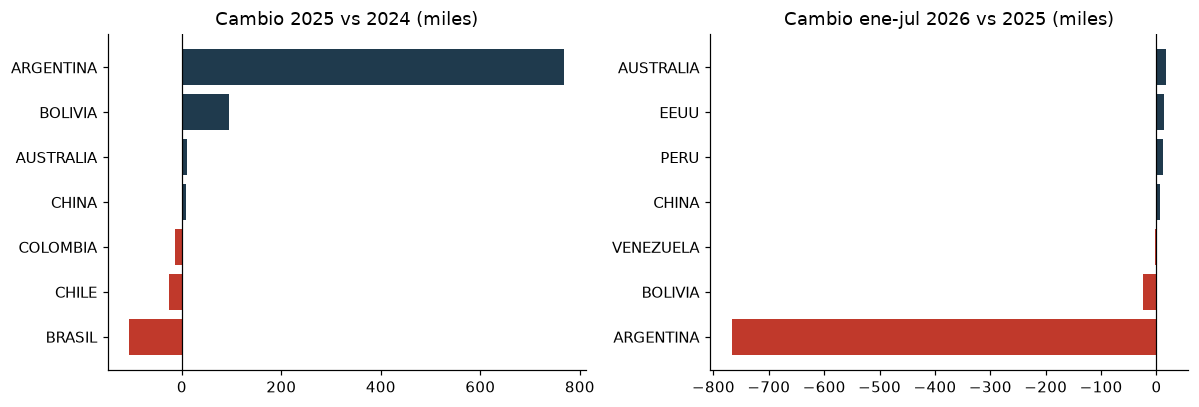

In [4]:
def acumulado(y, hasta=12): return hojas[(hojas.anio == y) & (hojas.mes <= hasta)].groupby("nacionalidad").llegadas.sum()
c25 = pd.DataFrame({"y24": acumulado(2024), "y25": acumulado(2025)}).fillna(0); c25["cambio"] = c25.y25 - c25.y24
c25["aporte_pct"] = 100 * c25.cambio / c25.cambio.sum()
c26 = pd.DataFrame({"y25": acumulado(2025, 7), "y26": acumulado(2026, 7)}).fillna(0); c26["cambio"] = c26.y26 - c26.y25
c26["var_pct"] = 100 * (c26.y26 / c26.y25 - 1); c26["aporte_pct"] = 100 * c26.cambio / c26.cambio.sum()
print(f"2025 vs 2024 (año completo): cambio total {c25.cambio.sum():+,.0f}")
print(c25.sort_values("cambio", ascending=False).head(5).round(1).to_string()); print(c25.sort_values("cambio").head(4).round(1).to_string())
print(f"\nEne-jul 2026 vs 2025: cambio total {c26.cambio.sum():+,.0f} ({100*c26.cambio.sum()/c26.y25.sum():+.1f}%)")
print(c26.sort_values("cambio").head(4).round(1).to_string()); print(c26.sort_values("cambio", ascending=False).head(6).round(1).to_string())

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
t1 = c25.sort_values("cambio"); t1 = pd.concat([t1.head(3), t1.tail(4)]); axs[0].barh(t1.index, t1.cambio / 1000, color=[ROJO if v < 0 else AZUL for v in t1.cambio]); axs[0].set_title("Cambio 2025 vs 2024 (miles)")
t2 = c26.sort_values("cambio"); t2 = pd.concat([t2.head(3), t2.tail(4)]); axs[1].barh(t2.index, t2.cambio / 1000, color=[ROJO if v < 0 else AZUL for v in t2.cambio]); axs[1].set_title("Cambio ene-jul 2026 vs 2025 (miles)")
for x in axs: x.axvline(0, color="black", lw=.8)
plt.tight_layout(); plt.show()

## 4. ¿Y el resto de los mercados, sin Argentina?

Acumulado ene-jul:
            total   argentina       resto  pct_argentina
2024 2,849,681.0 1,130,809.0 1,718,872.0           39.7
2025 3,662,026.0 1,931,583.0 1,730,443.0           52.7
2026 2,963,936.0 1,164,624.0 1,799,312.0           39.3

Sin Argentina: 2025 vs 2024 +0.7% | 2026 vs 2025 +4.0%  |  Argentina: 2025 vs 2024 +70.8% | 2026 vs 2025 -39.7%


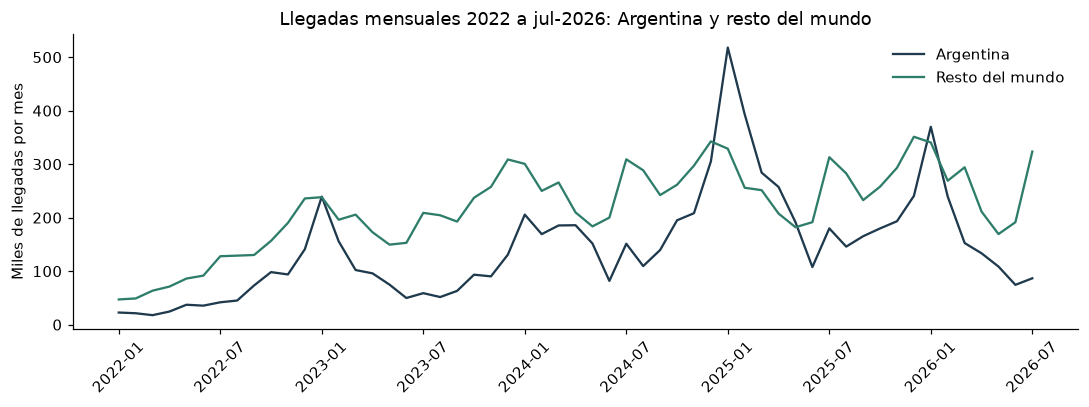

In [5]:
mens = pd.DataFrame({"total": total, "argentina": arg}).fillna(0); mens["resto"] = mens.total - mens.argentina
mens = mens.loc[2022:]; mens = mens[~((mens.index.get_level_values(0) == 2026) & (mens.index.get_level_values(1) > 7))]
def ytd(col, y, h=7): return mens.loc[y][col].loc[:h].sum()
tabla = pd.DataFrame({y: {"total": ytd("total", y), "argentina": ytd("argentina", y), "resto": ytd("resto", y)} for y in (2024, 2025, 2026)}).T
tabla["pct_argentina"] = 100 * tabla.argentina / tabla.total
print("Acumulado ene-jul:\n", tabla.round(1).to_string())
v = lambda c, y0, y1: 100 * (tabla.loc[y1, c] / tabla.loc[y0, c] - 1)
print(f"\nSin Argentina: 2025 vs 2024 {v('resto', 2024, 2025):+.1f}% | 2026 vs 2025 {v('resto', 2025, 2026):+.1f}%  |  Argentina: 2025 vs 2024 {v('argentina', 2024, 2025):+.1f}% | 2026 vs 2025 {v('argentina', 2025, 2026):+.1f}%")

x = [f"{y}-{m:02d}" for y, m in mens.index]
fig, ax = plt.subplots(figsize=(10, 3.8)); ax.plot(x, mens.argentina / 1000, color=AZUL, label="Argentina"); ax.plot(x, mens.resto / 1000, color=VERDE, label="Resto del mundo")
ax.set_xticks(range(0, len(x), 6)); ax.set_xticklabels(x[::6], rotation=45); ax.set_ylabel("Miles de llegadas por mes"); ax.legend(frameon=False)
ax.set_title("Llegadas mensuales 2022 a jul-2026: Argentina y resto del mundo"); plt.tight_layout(); plt.show()

In [6]:
# Variación interanual mes a mes (2026 vs 2025): Argentina contra el resto
yoy = pd.DataFrame({"argentina_pct": 100 * (mens.loc[2026].argentina / mens.loc[2025].argentina.loc[:7] - 1), "resto_pct": 100 * (mens.loc[2026].resto / mens.loc[2025].resto.loc[:7] - 1)})
yoy.index = MES[:7]; print(yoy.round(1).to_string())
print(f"\nMeses de 2026 con el resto del mundo sobre 2025: {(yoy.resto_pct > 0).sum()} de 7 | Argentina bajo 2025 en {(yoy.argentina_pct < 0).sum()} de 7")

     argentina_pct  resto_pct
Ene          -28.6        3.5
Feb          -39.1        5.1
Mar          -46.3       17.0
Abr          -48.2        1.7
May          -43.3       -7.0
Jun          -30.9       -0.0
Jul          -51.9        3.4

Meses de 2026 con el resto del mundo sobre 2025: 5 de 7 | Argentina bajo 2025 en 7 de 7


## 5. ¿Es distinta la estacionalidad de Argentina y la del resto?
Índice = llegadas del mes / promedio mensual del año, promediado en 2023, 2024 y 2025 (años completos).

     Argentina  Resto
Ene        1.9    1.2
Feb        1.4    0.9
Mar        1.1    1.0
Abr        1.0    0.8
May        0.8    0.7
Jun        0.5    0.7
Jul        0.7    1.1
Ago        0.6    1.1
Sep        0.7    0.9
Oct        0.9    1.0
Nov        1.0    1.2
Dic        1.4    1.4

Correlación entre los perfiles de Argentina y del resto: 0.50
Argentina: pico en Ene (1.91) y valle en Jun (0.47) | Resto: pico en Dic (1.37) y valle en May (0.70)


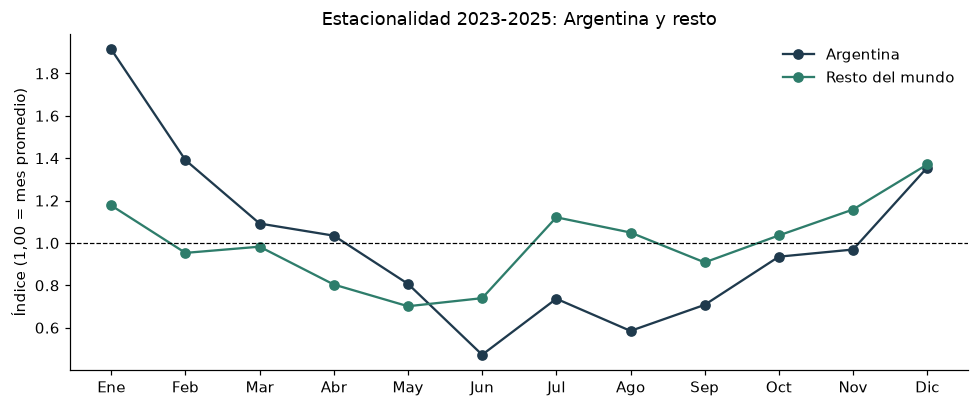

In [7]:
def indice(col):
    m = mens.loc[2023:2025][col].unstack(0); return (m / m.mean()).mean(axis=1)
idx = pd.DataFrame({"Argentina": indice("argentina"), "Resto": indice("resto")}); idx.index = MES
print(idx.round(2).to_string())
print(f"\nCorrelación entre los perfiles de Argentina y del resto: {idx.Argentina.corr(idx.Resto):.2f}")
print(f"Argentina: pico en {idx.Argentina.idxmax()} ({idx.Argentina.max():.2f}) y valle en {idx.Argentina.idxmin()} ({idx.Argentina.min():.2f}) | Resto: pico en {idx.Resto.idxmax()} ({idx.Resto.max():.2f}) y valle en {idx.Resto.idxmin()} ({idx.Resto.min():.2f})")
fig, ax = plt.subplots(figsize=(9, 3.8)); ax.plot(MES, idx.Argentina, marker="o", color=AZUL, label="Argentina"); ax.plot(MES, idx.Resto, marker="o", color=VERDE, label="Resto del mundo")
ax.axhline(1, color="black", lw=.8, ls="--"); ax.set_ylabel("Índice (1,00 = mes promedio)"); ax.set_title("Estacionalidad 2023-2025: Argentina y resto"); ax.legend(frameon=False); plt.tight_layout(); plt.show()

## 6. Escenarios ilustrativos para 2026 (no es un pronóstico)
Se separan los dos componentes: enero-julio es real; para agosto-diciembre se multiplica lo ocurrido en 2025 por una razón supuesta para Argentina y otra para el resto. Es un ejercicio de sensibilidad, no una predicción.

In [8]:
ar25 = mens.loc[2025].argentina.loc[8:].sum(); re25 = mens.loc[2025].resto.loc[8:].sum(); real26 = ytd("total", 2026); total25 = mens.loc[2025].total.sum()
r_arg = (mens.loc[2026].argentina / mens.loc[2025].argentina.loc[:7]); r_res = ytd("resto", 2026) / ytd("resto", 2025)
esc = pd.DataFrame({"escenario": ["Argentina como su peor mes de 2026", "Argentina como su acumulado ene-jul 2026", "Argentina como su mejor mes de 2026"],
                    "razon_argentina": [r_arg.min(), ytd("argentina", 2026) / ytd("argentina", 2025), r_arg.max()], "razon_resto": [r_res] * 3})
esc["total_2026"] = real26 + ar25 * esc.razon_argentina + re25 * esc.razon_resto; esc["var_vs_2025_pct"] = 100 * (esc.total_2026 / total25 - 1)
print(f"Real ene-jul 2026: {real26:,.0f} | ago-dic 2025: Argentina {ar25:,.0f} y resto {re25:,.0f} | total 2025: {total25:,.0f}")
print(esc.round(3).to_string(index=False))

Real ene-jul 2026: 2,963,936 | ago-dic 2025: Argentina 924,858 y resto 1,417,683 | total 2025: 6,004,567
                               escenario  razon_argentina  razon_resto  total_2026  var_vs_2025_pct
      Argentina como su peor mes de 2026              0.5          1.0 4,883,355.2            -18.7
Argentina como su acumulado ene-jul 2026              0.6          1.0 4,995,672.3            -16.8
     Argentina como su mejor mes de 2026              0.7          1.0 5,098,380.6            -15.1


## 7. Hallazgos
Las cifras se calculan con el código (no están escritas a mano).

In [9]:
pa = a.pct_argentina
print("1) PESO DE ARGENTINA")
print(f"   - Pasó de {pa[2022]:.1f}% (2022) a {pa[2024]:.1f}% (2024) y {pa[2025]:.1f}% (2025); en ene-jul 2026 vuelve a {tabla.loc[2026,'pct_argentina']:.1f}%. Máximo desde 2008: {pa.idxmax()} ({pa.max():.1f}%).")
print("\n2) CRECIMIENTO 2025 Y CAÍDA 2026")
print(f"   - Argentina aportó {c25.loc['ARGENTINA','aporte_pct']:.1f}% del aumento de 2025 ({c25.loc['ARGENTINA','cambio']:+,.0f} de {c25.cambio.sum():+,.0f}).")
print(f"   - En ene-jul 2026 el total cae {c26.cambio.sum():+,.0f} y Argentina {c26.loc['ARGENTINA','cambio']:+,.0f} ({c26.loc['ARGENTINA','aporte_pct']:.1f}% de la caída; {c26.loc['ARGENTINA','var_pct']:+.1f}%).")
print("\n3) SIN ARGENTINA")
resto_anual = 100 * (mens.loc[2025].resto.sum() / mens.loc[2024].resto.sum() - 1)
print(f"   - El resto del mundo cambia {resto_anual:+.1f}% en 2025 (año completo), {v('resto', 2024, 2025):+.1f}% en ene-jul 2025 y {v('resto', 2025, 2026):+.1f}% en ene-jul 2026; mejora en {(yoy.resto_pct > 0).sum()} de 7 meses.")
print("\n4) ESTACIONALIDAD")
print(f"   - Argentina: pico en {idx.Argentina.idxmax()} ({idx.Argentina.max():.2f}) y valle en {idx.Argentina.idxmin()} ({idx.Argentina.min():.2f}); resto: pico en {idx.Resto.idxmax()} ({idx.Resto.max():.2f}) y valle en {idx.Resto.idxmin()} ({idx.Resto.min():.2f}). Correlación de perfiles: {idx.Argentina.corr(idx.Resto):.2f}.")
print("\n5) ESCENARIOS 2026 (ilustrativos)")
print(f"   - Entre {esc.total_2026.min()/1e6:.2f} y {esc.total_2026.max()/1e6:.2f} millones de llegadas ({esc.var_vs_2025_pct.min():.1f}% a {esc.var_vs_2025_pct.max():.1f}% frente a 2025).")

1) PESO DE ARGENTINA
   - Pasó de 32.1% (2022) a 39.9% (2024) y 47.6% (2025); en ene-jul 2026 vuelve a 39.3%. Máximo desde 2008: 2017 (51.5%).

2) CRECIMIENTO 2025 Y CAÍDA 2026
   - Argentina aportó 100.4% del aumento de 2025 (+768,052 de +765,334).
   - En ene-jul 2026 el total cae -698,090 y Argentina -766,959 (109.9% de la caída; -39.7%).

3) SIN ARGENTINA
   - El resto del mundo cambia -0.1% en 2025 (año completo), +0.7% en ene-jul 2025 y +4.0% en ene-jul 2026; mejora en 5 de 7 meses.

4) ESTACIONALIDAD
   - Argentina: pico en Ene (1.91) y valle en Jun (0.47); resto: pico en Dic (1.37) y valle en May (0.70). Correlación de perfiles: 0.50.

5) ESCENARIOS 2026 (ilustrativos)
   - Entre 4.88 y 5.10 millones de llegadas (-18.7% a -15.1% frente a 2025).


## 8. Respuestas al encargo
(pendiente)

## 9. Recomendaciones accionables
(pendiente)

## 10. Limitaciones y cómo seguir
- **El archivo no explica causas:** muestra cuánto y cuándo cayó cada país, no por qué. Explicar la caída de Argentina requiere información externa (por ejemplo, tipo de cambio, precios relativos o conectividad).
- **Incluye chilenos residentes en el exterior** (nacionalidad "CHILE") y las cifras son preliminares desde julio de 2020: pueden revisarse.
- **2026 llega hasta julio:** los escenarios suponen un comportamiento de agosto a diciembre que no se conoce.
- **El índice estacional usa 3 años completos** (2023-2025), con 2023 todavía en recuperación.
- **Siguiente paso:** cruzar con el detalle por paso fronterizo (disponible en el mismo archivo) y con alojamiento (EMAT) y visitación a parques (SNASPE).